In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import geopandas as gpd

In [119]:
discharge = xr.open_dataset('DATA/GreenlandData/GL_discharge.nc')
discharge = discharge.set_coords('region_name')

runoff = xr.open_dataset('DATA/GreenlandData/GL_runoff.nc')
runoff = runoff.set_coords('region_name')
total_runoff = ( runoff["surface_runoff_from_ice"]
    + runoff["surface_runoff_from_land"]
    + runoff["subglacial_discharge_from_ice"]
    + runoff["subglacial_discharge_from_land"] )

mouginot_regions = gpd.read_file('DATA/GreenlandData/GL_regions_4326.gpkg')
mouginot_regions = mouginot_regions.set_index('label')

# Projection to use for plots
mouginot_regions_plot = mouginot_regions.to_crs("EPSG:3413")  # EPSG 3413 is a good general-purpose polar projection, but not equal area
# Projection to use for area calculations
mouginot_regions_equalarea = mouginot_regions.to_crs("EPSG:3575") 

region_names = mouginot_regions.index.to_numpy()

runoff
discharge

<xarray.Dataset> Size: 17kB
Dimensions:      (region: 7, time: 186)
Coordinates:
  * region       (region) int64 56B 1 2 3 4 5 6 7
    region_name  (region) <U2 56B ...
  * time         (time) datetime64[ns] 1kB 1840-01-01 1841-01-01 ... 2025-01-01
Data variables:
    discharge    (region, time) float64 10kB ...
    err          (region, time) float32 5kB ...
Attributes: (12/17)
    featureType:           timeSeries
    title:                 Greenland ice sheet discharge by Mouginot region
    summary:               Greenland ice sheet mass balance from 1840 through...
    keywords:              Greenland; Mass; Mass balance
    source:                doi:10.5281/ZENODO.8052519
    creator_name:          Ken Mankoff
    ...                    ...
    Conventions:           CF-1.8
    date_created:          20250421T155603Z
    history:               See GL_discharge.org
    source_code_workbook:  GL_discharge.org
    DOI:                   https://doi.org/10.5281/zenodo.14020895
    original_data_source:  Mankoff (2020) https://doi.org/10.5194/essd-12-136...

### Explore freshwater source data

Text(0.5, 1.0, 'Solid discharge, Gt yr-1')

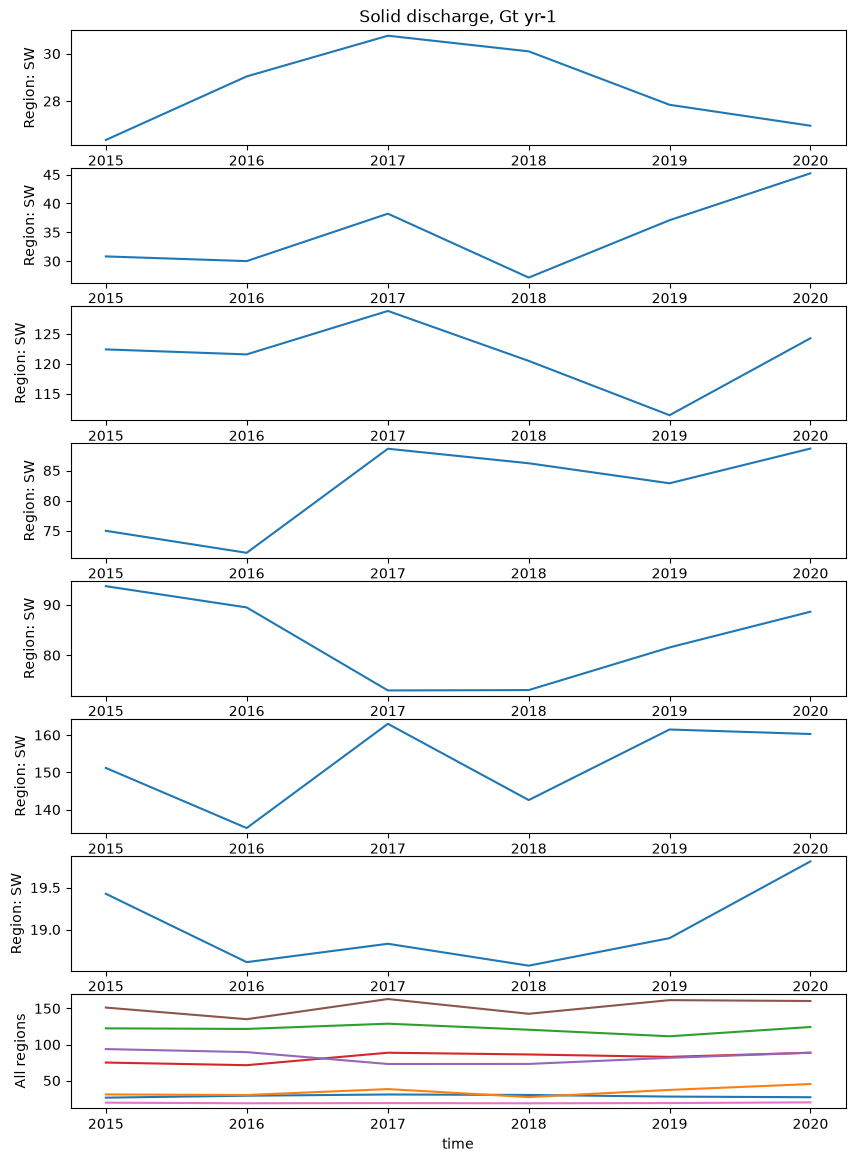

In [43]:
fig, ax = plt.subplots(8,1, figsize=(10,14))

for i, region in enumerate(region_names):
    #print(region)
    #print(i)

    discharge.sel(region_name=region, time=slice("2015-01-01", "2020-12-31"))['discharge'].plot(ax=ax[i])
    ax[i].set_ylabel(f'Region: {region_name}')
    ax[i].set_title(' ')

    #ax[i].set_ylim(0,160)

    discharge.sel(region_name=region, time=slice("2015-01-01", "2020-12-31"))['discharge'].plot(ax=ax[7])

ax[7].set_ylabel(f'All regions')
ax[7].set_title(' ')
ax[0].set_title('Solid discharge, Gt yr-1' )


Text(0.5, 1.0, 'Solid discharge, Gt yr-1')

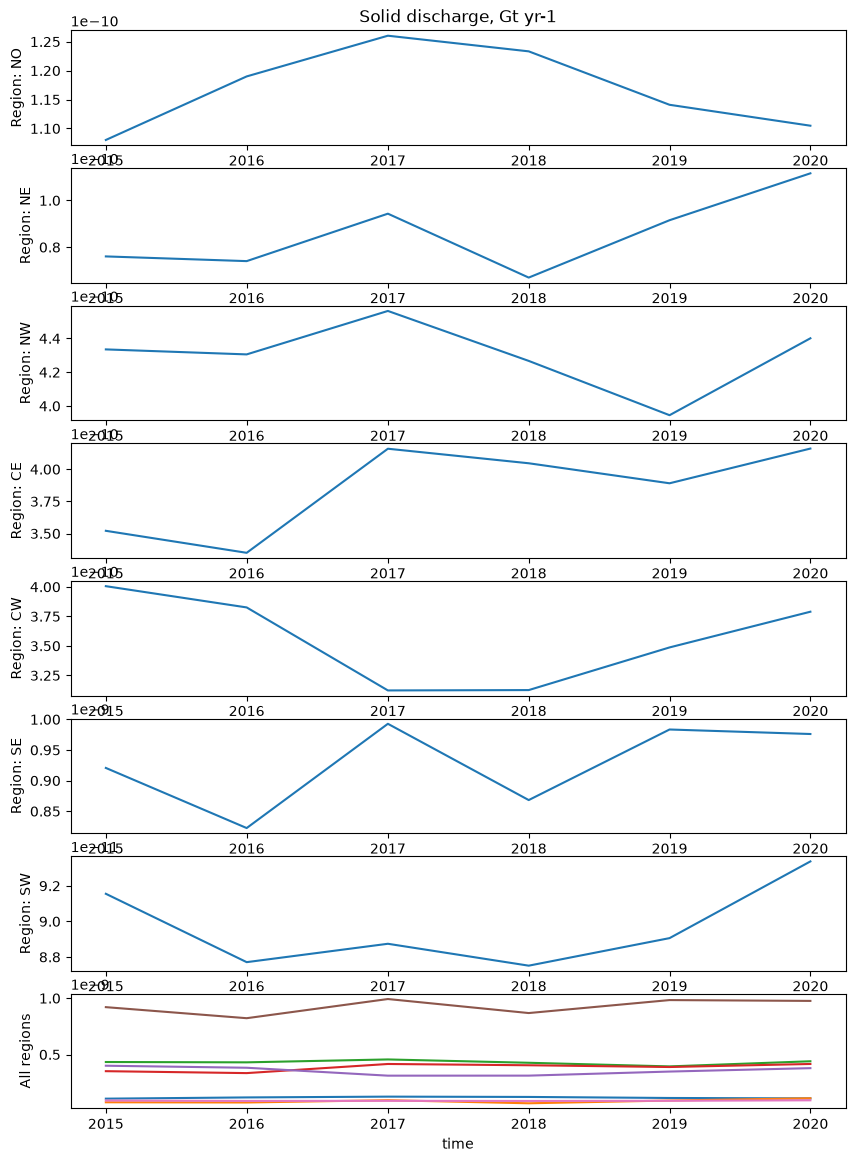

In [57]:
# Does the discharge depend on region area? I'd like to look at coastline as well but area is an okay proxy for now
fig, ax = plt.subplots(8,1, figsize=(10,14))

for i, region in enumerate(region_names):
    #print(region)
    #print(i)

    (discharge.sel(region_name=region, time=slice("2015-01-01", "2020-12-31"))['discharge']/mouginot_regions_equalarea.area.loc[region]).plot(ax=ax[i])
    ax[i].set_ylabel(f'Region: {region}')
    ax[i].set_title(' ')

    #ax[i].set_ylim(0,160)

    (discharge.sel(region_name=region, time=slice("2015-01-01", "2020-12-31"))['discharge']/mouginot_regions_equalarea.area.loc[region]).plot(ax=ax[7])

ax[7].set_ylabel(f'All regions')
ax[7].set_title(' ')
ax[0].set_title('Solid discharge, Gt yr-1' )


This shows that the solid discharge varies greatly depending on the region, up to almost an order of magnitude between the lowest and highest discharge regions. 

This may be caused by different precipitation levels, temperature/latitude, region areas, etc.

Text(0.5, 1.0, 'Total liquid runoff, m3 s-1')

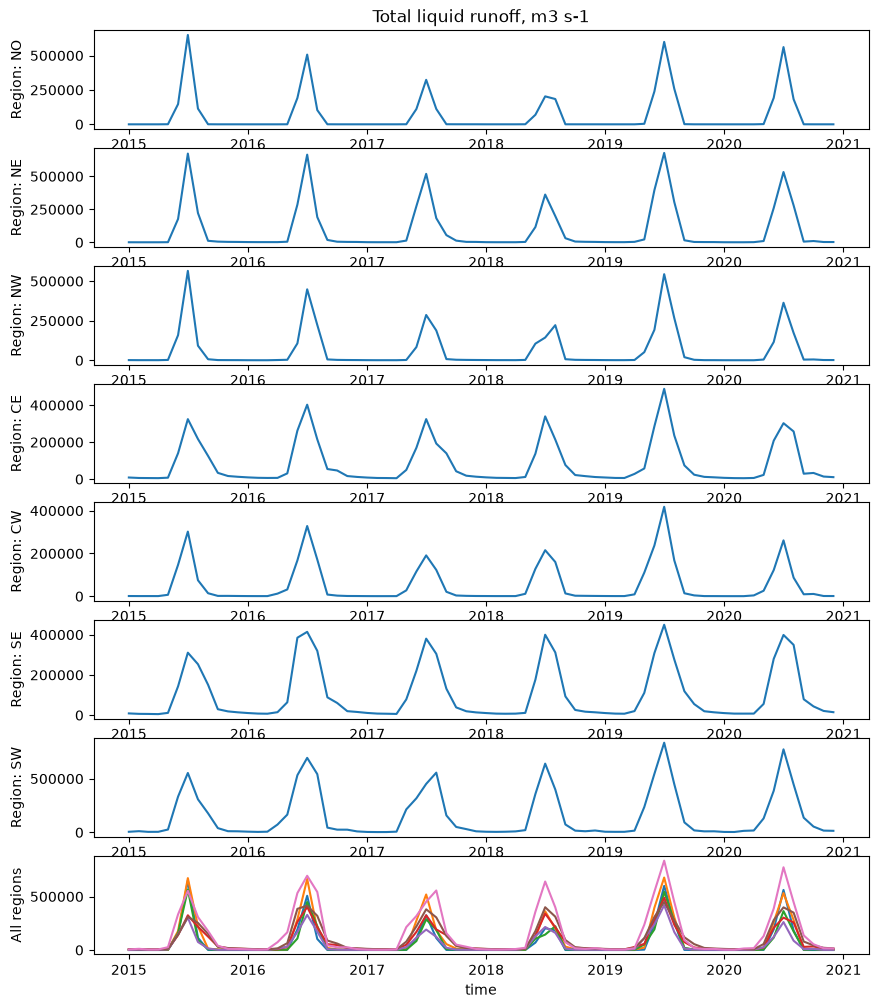

In [47]:
fig, ax = plt.subplots(8,1, figsize=(10,12))

for i, region in enumerate(region_names):
    #print(region)
    #print(i)

    total_runoff.sel(region_name=region, time=slice("2015-01-01", "2020-12-31")).plot(ax=ax[i])
    #ax[i].set_ylim(0,160)
    ax[i].set_ylabel(f'Region: {region}')
    ax[i].set_title(' ')

    total_runoff.sel(region_name=region, time=slice("2015-01-01", "2020-12-31")).plot(ax=ax[7])

ax[7].set_ylabel(f'All regions')
ax[7].set_title(' ')
ax[0].set_title('Total liquid runoff, m3 s-1' )

Liquid runoff varies less by region

Index(['NO', 'NE', 'NW', 'CE', 'CW', 'SE', 'SW'], dtype='str', name='label')


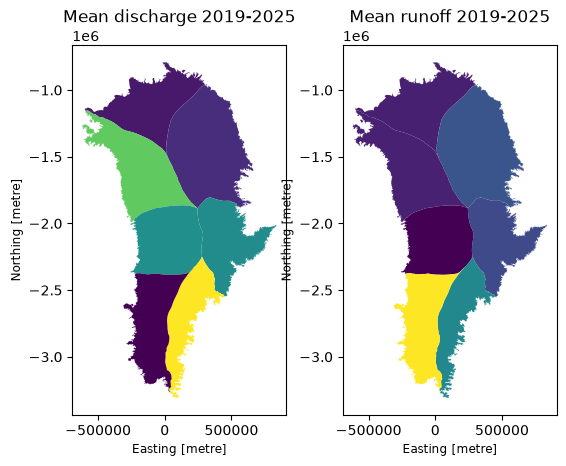

Text(0.5, 1.0, 'Subglacial land')

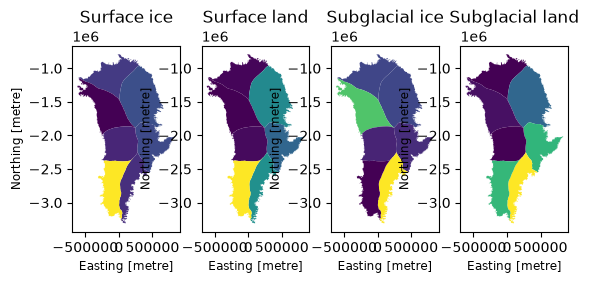

In [118]:
mouginot_regions_plot['mean_recent_discharge'] = np.array([discharge.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')['discharge']
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values])
mouginot_regions_plot['mean_recent_runoff'] = np.array([total_runoff.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values])


fig, ax = plt.subplots(1, 2)
mouginot_regions_plot.plot(column=mouginot_regions_plot['mean_recent_discharge'], ax=ax[0])
mouginot_regions_plot.plot(column=mouginot_regions_plot['mean_recent_runoff'], ax=ax[1])

ax[0].set_title('Mean discharge 2019-2025')
ax[1].set_title('Mean runoff 2019-2025')

plt.show()


fig, ax = plt.subplots(1, 4)
mouginot_regions_plot.plot(column=np.array([runoff.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')['surface_runoff_from_ice']
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values]), ax=ax[0])
mouginot_regions_plot.plot(column=np.array([runoff.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')['surface_runoff_from_land']
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values]), ax=ax[1])
mouginot_regions_plot.plot(column=np.array([runoff.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')['subglacial_discharge_from_ice']
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values]), ax=ax[2])
mouginot_regions_plot.plot(column=np.array([runoff.sel(time=slice("2019-01-01", "2024-12-31"))
                                                .mean(dim='time')['subglacial_discharge_from_land']
                                                 .sel(region_name=region).values for region in mouginot_regions_plot.index.values]), ax=ax[3])

ax[0].set_title('Surface ice')
ax[1].set_title('Surface land')
ax[2].set_title('Subglacial ice')
ax[3].set_title('Subglacial land')




I'd love to check how this varies with area and, especially, cosatline, but for the mini-project I don't have time.